PART 1: CORE TASK REQUIREMENTS (STEPS 1 TO 8)
KNN IRIS FLOWER CLASSIFICATION
Course: Artificial Intelligence Lab (CE-7)

[Step 1] Dataset Successfully Loaded From: C:\CE\CE-7\GitHub\AI LAB\AI LAB 6\Iris.csv
Initial Dataset Shape: (150, 5)

First 5 Rows of Dataset:
   sepal_length  sepal_width  petal_length  petal_width      species
0           5.1          3.5           1.4          0.2  Iris-setosa
1           4.9          3.0           1.4          0.2  Iris-setosa
2           4.7          3.2           1.3          0.2  Iris-setosa
3           4.6          3.1           1.5          0.2  Iris-setosa
4           5.0          3.6           1.4          0.2  Iris-setosa

------------------------------------------------------------------------------------------
[Step 2 & 3] Feature Identification, EDA & Preprocessing Check
------------------------------------------------------------------------------------------

Input Features (X): ['sepal_length', 'sepal_width', 'petal_length', 'petal

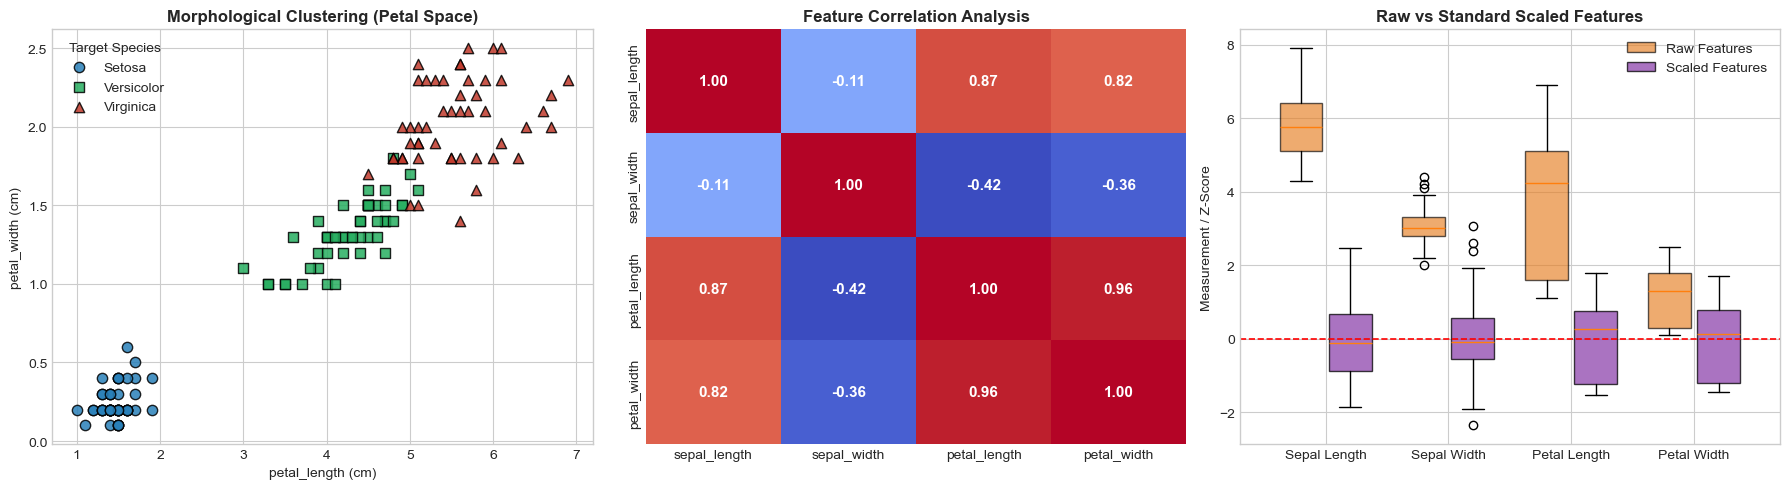


[Step 5, 6 & 7] KNN MODEL EVALUATION
Comparison of K = 3, K = 5 and K = 7

Model Comparison:
K Value Test Accuracy Correct Predictions Weighted Precision Weighted Recall Weighted F1-Score  Misclassified Flowers
  K = 3        93.33%               28/30             94.44%          93.33%            93.27%                      2
  K = 5        93.33%               28/30             94.44%          93.33%            93.27%                      2
  K = 7        96.67%               29/30             96.97%          96.67%            96.66%                      1

Best K Based on Test Accuracy: K = 7
Best Test Accuracy: 96.67%

Detailed Classification Report for K = 7:
              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        10
  Versicolor       0.91      1.00      0.95        10
   Virginica       1.00      0.90      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30


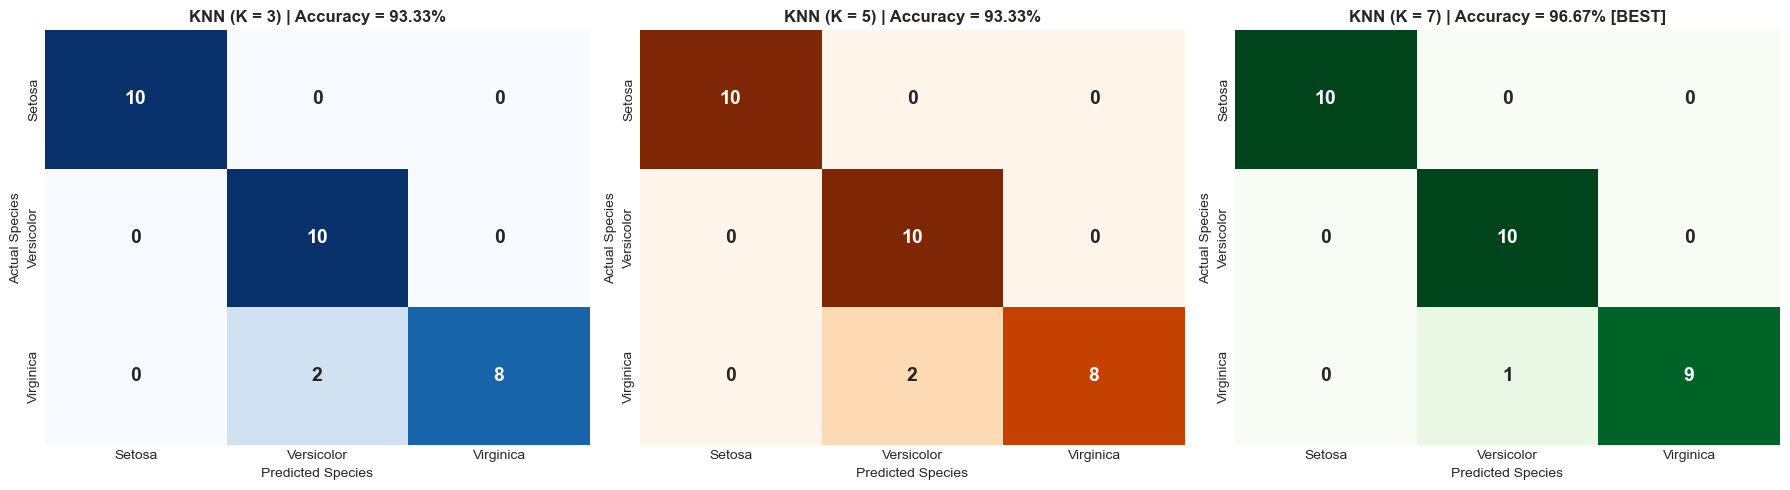


[Step 8] BEST K IDENTIFICATION & KNN THEORY

1. Best K on the Selected Test Set:
   K = 7 achieved the highest test accuracy of 96.67%.
   It correctly classified 29 out of 30 flowers.

2. Why KNN Classifies Using Nearest Neighbors:
   KNN is a non-parametric and instance-based learning algorithm.
   It assumes that samples with similar characteristics are located
   close to each other in the feature space.

3. Euclidean Distance Formula:
   d(xq, xi) = sqrt(sum((xq,j - xi,j)^2))

4. Majority Voting:
   KNN finds the K closest training samples and assigns the test
   sample to the class receiving the highest number of votes.

******************************************************************************************
PART 2: ADVANCED ENGINEERING INNOVATIONS
******************************************************************************************

1. Hyperparameter Sensitivity Sweep (K = 1 to 25)
2. Uniform vs Distance-Weighted KNN
3. 5-Fold Stratified Cross-Validation
4. PCA Decision 

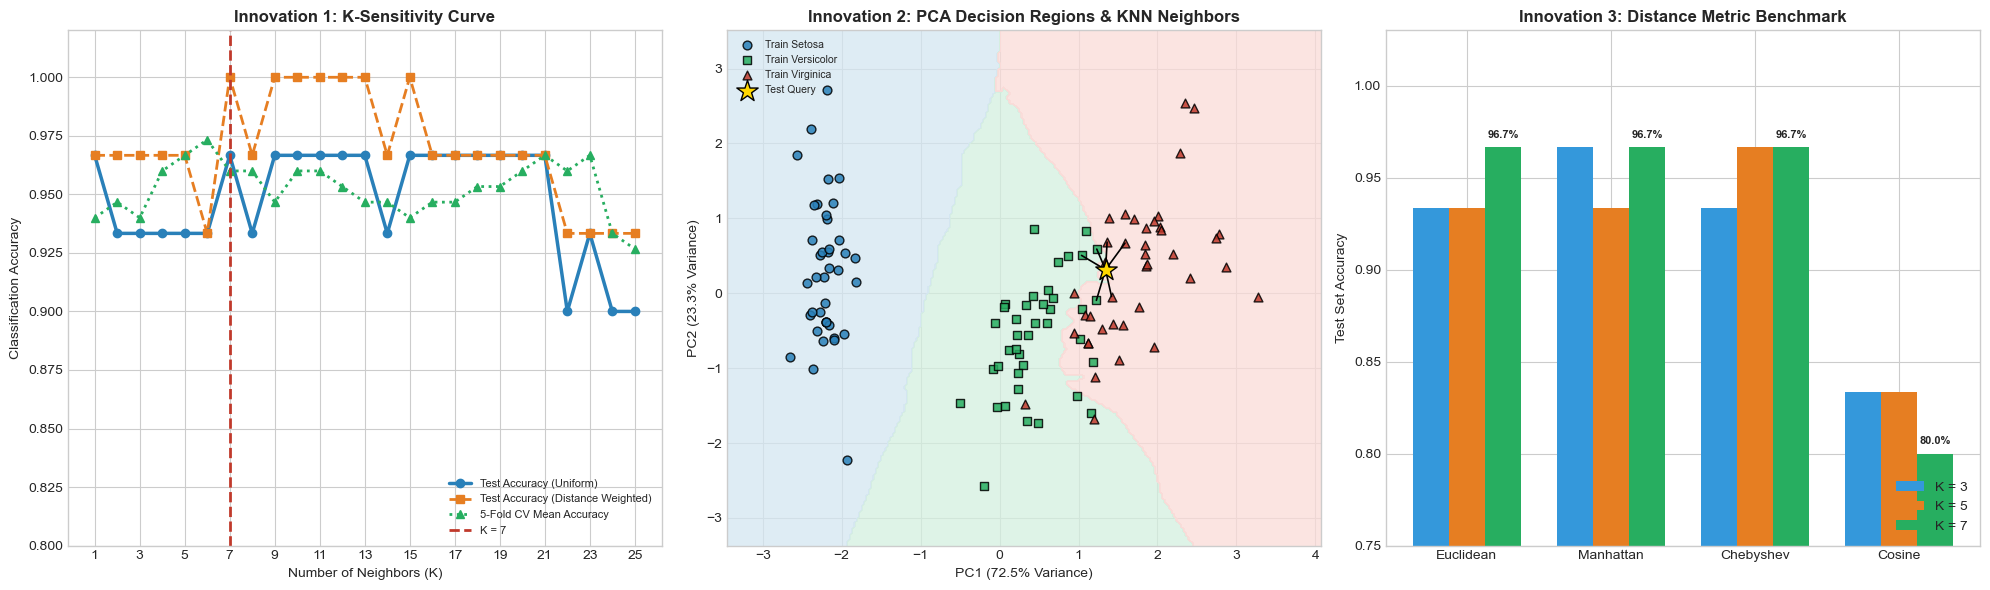


FINAL LAB SUMMARY
Dataset Used                 : C:\CE\CE-7\GitHub\AI LAB\AI LAB 6\Iris.csv
Total Samples                : 150
Training Samples             : 120
Testing Samples              : 30
Best K from K=3,5,7          : K = 7
Best Test Accuracy           : 96.67%
Best 5-Fold CV K             : K = 6
Best 5-Fold CV Accuracy      : 97.33%

All KNN classification requirements and advanced analyses completed successfully.


In [6]:
# =========================================================================
# LAB 6 - QUESTION 2: K-NEAREST NEIGHBORS (KNN) — IRIS FLOWER CLASSIFICATION
# Course: Artificial Intelligence Lab (CE-7)
# Complete Single-Cell Solution
# Part 1: Core Requirements (1-8)
# Part 2: Advanced Engineering Innovations
# =========================================================================

import os
import glob
import warnings

warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Set plot style safely
if 'seaborn-v0_8-whitegrid' in plt.style.available:
    plt.style.use('seaborn-v0_8-whitegrid')
else:
    plt.style.use('default')


# =========================================================================
# PART 1: CORE TASK REQUIREMENTS
# =========================================================================

print("=" * 90)
print("PART 1: CORE TASK REQUIREMENTS (STEPS 1 TO 8)")
print("KNN IRIS FLOWER CLASSIFICATION")
print("Course: Artificial Intelligence Lab (CE-7)")
print("=" * 90)


# -------------------------------------------------------------------------
# REQUIREMENT 1: LOAD THE IRIS DATASET
# -------------------------------------------------------------------------

folder_path = r"C:\CE\CE-7\GitHub\AI LAB\AI LAB 6"

candidate_paths = [
    os.path.join(folder_path, "Iris.csv"),
    os.path.join(folder_path, "iris.csv"),
    "Iris.csv",
    "iris.csv"
]

df = None
loaded_source = None

# Try loading from known file paths
for path in candidate_paths:
    if os.path.exists(path):
        df = pd.read_csv(path)
        loaded_source = path
        break

# Search for any CSV file containing "iris" in its name
if df is None and os.path.exists(folder_path):
    for file in glob.glob(os.path.join(folder_path, "*.csv")):
        if "iris" in os.path.basename(file).lower():
            df = pd.read_csv(file)
            loaded_source = file
            break

# Fallback to Scikit-learn dataset
if df is None:
    iris_sk = load_iris()

    df = pd.DataFrame(
        iris_sk.data,
        columns=[
            'SepalLengthCm',
            'SepalWidthCm',
            'PetalLengthCm',
            'PetalWidthCm'
        ]
    )

    df['Species'] = [
        iris_sk.target_names[i]
        for i in iris_sk.target
    ]

    loaded_source = "Scikit-learn built-in load_iris()"

print(f"\n[Step 1] Dataset Successfully Loaded From: {loaded_source}")
print(f"Initial Dataset Shape: {df.shape}")

print("\nFirst 5 Rows of Dataset:")
print(df.head())


# -------------------------------------------------------------------------
# REQUIREMENTS 2 & 3: FEATURES, TARGET AND EDA
# -------------------------------------------------------------------------

print("\n" + "-" * 90)
print("[Step 2 & 3] Feature Identification, EDA & Preprocessing Check")
print("-" * 90)

# Remove ID column if present
id_cols = [
    column for column in df.columns
    if column.lower() in ['id', 'unnamed: 0']
]

if id_cols:
    print(f"\nPreprocessing: Dropping identifier column(s): {id_cols}")
    df_clean = df.drop(columns=id_cols)
else:
    df_clean = df.copy()

# Identify target column
target_candidates = [
    column for column in df_clean.columns
    if column.lower() in ['species', 'variety', 'class', 'target']
]

if target_candidates:
    target_col = target_candidates[0]
else:
    target_col = df_clean.columns[-1]

# Separate features and target
X = df_clean.drop(columns=[target_col])
y_raw = df_clean[target_col]

# Make sure features are numeric
X = X.apply(pd.to_numeric, errors='coerce')

# Encode class labels
le = LabelEncoder()
y = le.fit_transform(y_raw)

class_names = [
    str(class_name).replace('Iris-', '').capitalize()
    for class_name in le.classes_
]

print(f"\nInput Features (X): {list(X.columns)}")
print(f"Feature Shape: {X.shape}")

print(f"\nTarget Variable: {target_col}")
print("Encoded Classes:")

for index, name in enumerate(class_names):
    print(f"  {name} = {index}")

# Missing values
missing_values = int(X.isnull().sum().sum())

print(f"\nMissing Values Count: {missing_values}")

# Remove rows with missing values if any exist
if missing_values > 0:
    print("Missing values detected. Removing incomplete rows.")

    valid_rows = X.notna().all(axis=1)
    X = X.loc[valid_rows].reset_index(drop=True)
    y = y[valid_rows]

# Class balance
print("\nClass Balance Check:")

for index, name in enumerate(class_names):
    count = int((y == index).sum())
    percentage = (y == index).mean() * 100

    print(
        f"Class {index} ({name}): "
        f"{count} samples ({percentage:.1f}%)"
    )

# Summary statistics
print("\nSummary Statistics of Raw Features:")
print(
    X.describe().T[
        ['count', 'mean', 'std', 'min', '50%', 'max']
    ].round(2)
)

print("\nWhy Feature Scaling Is Required:")
print(
    "KNN calculates distances between samples. Features with larger "
    "numerical ranges can dominate the Euclidean distance calculation. "
    "StandardScaler transforms features to a comparable scale."
)


# -------------------------------------------------------------------------
# REQUIREMENT 4: TRAIN-TEST SPLIT AND FEATURE SCALING
# -------------------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\n" + "-" * 90)
print("[Step 4] Stratified Train-Test Split (80/20) & Feature Scaling")
print("-" * 90)

print(f"Training Samples: {X_train.shape[0]}")
print(f"Testing Samples : {X_test.shape[0]}")


# =========================================================================
# VISUALIZATION FIGURE 1
# =========================================================================

print("\nGenerating Figure 1: EDA and Feature Scaling...")

fig1, axes1 = plt.subplots(1, 3, figsize=(18, 5))

colors_species = ['#2980b9', '#27ae60', '#c0392b']
markers_species = ['o', 's', '^']

# Plot 1: Petal clustering
for index, species_name in enumerate(class_names):

    mask = (y == index)

    axes1[0].scatter(
        X.iloc[mask, 2],
        X.iloc[mask, 3],
        color=colors_species[index],
        marker=markers_species[index],
        s=55,
        alpha=0.85,
        edgecolor='black',
        label=species_name
    )

axes1[0].set_title(
    'Morphological Clustering (Petal Space)',
    fontweight='bold'
)

axes1[0].set_xlabel(f'{X.columns[2]} (cm)')
axes1[0].set_ylabel(f'{X.columns[3]} (cm)')
axes1[0].legend(title='Target Species')


# Plot 2: Correlation heatmap
sns.heatmap(
    X.corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    cbar=False,
    ax=axes1[1],
    annot_kws={"size": 11, "weight": "bold"}
)

axes1[1].set_title(
    'Feature Correlation Analysis',
    fontweight='bold'
)


# Plot 3: Raw vs Scaled features
axes1[2].boxplot(
    [X_train.iloc[:, i] for i in range(X_train.shape[1])],
    positions=[1, 2, 3, 4],
    widths=0.35,
    patch_artist=True,
    boxprops=dict(facecolor='#e67e22', alpha=0.65)
)

axes1[2].boxplot(
    [X_train_scaled[:, i] for i in range(X_train_scaled.shape[1])],
    positions=[1.4, 2.4, 3.4, 4.4],
    widths=0.35,
    patch_artist=True,
    boxprops=dict(facecolor='#8e44ad', alpha=0.75)
)

axes1[2].axhline(
    0,
    color='red',
    linestyle='--',
    linewidth=1.2
)

axes1[2].set_xticks([1.2, 2.2, 3.2, 4.2])

axes1[2].set_xticklabels(
    ['Sepal Length', 'Sepal Width', 'Petal Length', 'Petal Width']
)

axes1[2].set_title(
    'Raw vs Standard Scaled Features',
    fontweight='bold'
)

axes1[2].set_ylabel('Measurement / Z-Score')

legend_patches = [
    Patch(
        facecolor='#e67e22',
        alpha=0.65,
        edgecolor='black',
        label='Raw Features'
    ),
    Patch(
        facecolor='#8e44ad',
        alpha=0.75,
        edgecolor='black',
        label='Scaled Features'
    )
]

axes1[2].legend(
    handles=legend_patches,
    loc='upper right'
)

plt.tight_layout()
plt.show()


# -------------------------------------------------------------------------
# REQUIREMENTS 5, 6 & 7: TRAIN AND COMPARE K = 3, 5, 7
# -------------------------------------------------------------------------

print("\n" + "=" * 90)
print("[Step 5, 6 & 7] KNN MODEL EVALUATION")
print("Comparison of K = 3, K = 5 and K = 7")
print("=" * 90)

k_values = [3, 5, 7]

k_summary_rows = []
predictions_dict = {}
models_dict = {}
accuracy_dict = {}

for k in k_values:

    knn_model = KNeighborsClassifier(
        n_neighbors=k,
        metric='euclidean',
        weights='uniform'
    )

    knn_model.fit(X_train_scaled, y_train)

    y_pred_k = knn_model.predict(X_test_scaled)

    # Store model and predictions
    models_dict[k] = knn_model
    predictions_dict[k] = y_pred_k

    # Calculate metrics
    acc = accuracy_score(y_test, y_pred_k)

    prec = precision_score(
        y_test,
        y_pred_k,
        average='weighted',
        zero_division=0
    )

    rec = recall_score(
        y_test,
        y_pred_k,
        average='weighted',
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred_k,
        average='weighted',
        zero_division=0
    )

    errors = int((y_test != y_pred_k).sum())

    accuracy_dict[k] = acc

    k_summary_rows.append({
        'K Value': f'K = {k}',
        'Test Accuracy': f'{acc * 100:.2f}%',
        'Correct Predictions': f'{len(y_test) - errors}/{len(y_test)}',
        'Weighted Precision': f'{prec * 100:.2f}%',
        'Weighted Recall': f'{rec * 100:.2f}%',
        'Weighted F1-Score': f'{f1 * 100:.2f}%',
        'Misclassified Flowers': errors
    })

k_comp_df = pd.DataFrame(k_summary_rows)

print("\nModel Comparison:")
print(k_comp_df.to_string(index=False))


# Find actual best K
best_k = max(accuracy_dict, key=accuracy_dict.get)

print(f"\nBest K Based on Test Accuracy: K = {best_k}")
print(f"Best Test Accuracy: {accuracy_dict[best_k] * 100:.2f}%")


# Classification report
print(f"\nDetailed Classification Report for K = {best_k}:")

print(
    classification_report(
        y_test,
        predictions_dict[best_k],
        target_names=class_names,
        zero_division=0
    )
)


# =========================================================================
# VISUALIZATION FIGURE 2: CONFUSION MATRICES
# =========================================================================

print("\nGenerating Figure 2: Confusion Matrices...")

fig2, axes2 = plt.subplots(1, 3, figsize=(18, 5))

cmaps_k = ['Blues', 'Oranges', 'Greens']

for index, k_value in enumerate(k_values):

    y_pred_k = predictions_dict[k_value]

    acc_k = accuracy_score(
        y_test,
        y_pred_k
    )

    cm_k = confusion_matrix(
        y_test,
        y_pred_k
    )

    sns.heatmap(
        cm_k,
        annot=True,
        fmt='d',
        cmap=cmaps_k[index],
        cbar=False,
        ax=axes2[index],
        xticklabels=class_names,
        yticklabels=class_names,
        annot_kws={
            "size": 14,
            "weight": "bold"
        }
    )

    best_tag = ""

    if k_value == best_k:
        best_tag = " [BEST]"

    axes2[index].set_title(
        f'KNN (K = {k_value}) | Accuracy = {acc_k * 100:.2f}%{best_tag}',
        fontweight='bold'
    )

    axes2[index].set_xlabel('Predicted Species')
    axes2[index].set_ylabel('Actual Species')

plt.tight_layout()
plt.show()


# -------------------------------------------------------------------------
# REQUIREMENT 8: BEST K AND THEORETICAL JUSTIFICATION
# -------------------------------------------------------------------------

print("\n" + "=" * 90)
print("[Step 8] BEST K IDENTIFICATION & KNN THEORY")
print("=" * 90)

best_errors = int(
    (y_test != predictions_dict[best_k]).sum()
)

print(
    f"\n1. Best K on the Selected Test Set:\n"
    f"   K = {best_k} achieved the highest test accuracy of "
    f"{accuracy_dict[best_k] * 100:.2f}%.\n"
    f"   It correctly classified "
    f"{len(y_test) - best_errors} out of {len(y_test)} flowers."
)

print(
    "\n2. Why KNN Classifies Using Nearest Neighbors:\n"
    "   KNN is a non-parametric and instance-based learning algorithm.\n"
    "   It assumes that samples with similar characteristics are located\n"
    "   close to each other in the feature space."
)

print(
    "\n3. Euclidean Distance Formula:\n"
    "   d(xq, xi) = sqrt(sum((xq,j - xi,j)^2))"
)

print(
    "\n4. Majority Voting:\n"
    "   KNN finds the K closest training samples and assigns the test\n"
    "   sample to the class receiving the highest number of votes."
)


# =========================================================================
# PART 2: ADVANCED ENGINEERING INNOVATIONS
# =========================================================================

print("\n" + "*" * 90)
print("PART 2: ADVANCED ENGINEERING INNOVATIONS")
print("*" * 90)

print(
    "\n1. Hyperparameter Sensitivity Sweep (K = 1 to 25)"
    "\n2. Uniform vs Distance-Weighted KNN"
    "\n3. 5-Fold Stratified Cross-Validation"
    "\n4. PCA Decision Boundaries"
    "\n5. Multi-Metric Distance Benchmark"
    "\n6. K = 7 Nearest Neighbor Audit"
)


# -------------------------------------------------------------------------
# INNOVATION 1: K SWEEP AND DISTANCE WEIGHTING
# -------------------------------------------------------------------------

k_range = range(1, 26)

acc_uniform = []
acc_weighted = []
cv_uniform = []

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Scale complete dataset for cross-validation
scaler_all = StandardScaler()
X_all_scaled = scaler_all.fit_transform(X)

for k in k_range:

    # Uniform KNN
    clf_uniform = KNeighborsClassifier(
        n_neighbors=k,
        weights='uniform'
    )

    clf_uniform.fit(
        X_train_scaled,
        y_train
    )

    pred_uniform = clf_uniform.predict(
        X_test_scaled
    )

    acc_uniform.append(
        accuracy_score(
            y_test,
            pred_uniform
        )
    )

    # Distance-weighted KNN
    clf_weighted = KNeighborsClassifier(
        n_neighbors=k,
        weights='distance'
    )

    clf_weighted.fit(
        X_train_scaled,
        y_train
    )

    pred_weighted = clf_weighted.predict(
        X_test_scaled
    )

    acc_weighted.append(
        accuracy_score(
            y_test,
            pred_weighted
        )
    )

    # Cross-validation
    cv_scores = cross_val_score(
        KNeighborsClassifier(
            n_neighbors=k
        ),
        X_all_scaled,
        y,
        cv=skf,
        scoring='accuracy'
    )

    cv_uniform.append(
        cv_scores.mean()
    )


# Find best cross-validation K
best_cv_index = int(np.argmax(cv_uniform))
best_cv_k = list(k_range)[best_cv_index]
best_cv_accuracy = cv_uniform[best_cv_index]

print("\n[Innovation 1] Results:")

print(
    f"Uniform KNN (K = 7) Test Accuracy: "
    f"{acc_uniform[6] * 100:.2f}%"
)

print(
    f"Distance-Weighted KNN (K = 7) Test Accuracy: "
    f"{acc_weighted[6] * 100:.2f}%"
)

print(
    f"Peak 5-Fold CV Accuracy: "
    f"{best_cv_accuracy * 100:.2f}% "
    f"at K = {best_cv_k}"
)


# -------------------------------------------------------------------------
# INNOVATION 4: BOTANICAL DECISION SUPPORT SYSTEM
# -------------------------------------------------------------------------

print("\n" + "-" * 90)
print("[Innovation 4] K = 7 NEAREST-NEIGHBOR AUDIT")
print("-" * 90)

# This line had the indentation error in your original code.
# It must start at the left margin.

audit_k = 7

best_knn = models_dict[audit_k]

dists_test, indices_test = best_knn.kneighbors(
    X_test_scaled,
    n_neighbors=audit_k
)

probs_test = best_knn.predict_proba(
    X_test_scaled
)

# Safe sample selection
sample_indices = [0, 5, 12, 23, 25]
sample_indices = [
    i for i in sample_indices
    if i < len(y_test)
]

for sample_i in sample_indices:

    true_sp = class_names[y_test[sample_i]]

    pred_sp = class_names[
        predictions_dict[audit_k][sample_i]
    ]

    confidence = probs_test[sample_i].max() * 100

    mean_distance = dists_test[sample_i].mean()

    neighbor_votes = [
        class_names[y_train[index]]
        for index in indices_test[sample_i]
    ]

    vote_summary = {
        species: neighbor_votes.count(species)
        for species in class_names
        if neighbor_votes.count(species) > 0
    }

    print(
        f"Test Flower #{sample_i:02d} | "
        f"True: {true_sp:10s} | "
        f"Predicted: {pred_sp:10s} | "
        f"Confidence: {confidence:5.1f}% | "
        f"Mean Distance: {mean_distance:.3f} | "
        f"7-NN Votes: {vote_summary}"
    )


# =========================================================================
# VISUALIZATION FIGURE 3: ADVANCED INNOVATIONS DASHBOARD
# =========================================================================

print("\nGenerating Figure 3: Advanced Engineering Innovations...")

fig3, axes3 = plt.subplots(
    1,
    3,
    figsize=(20, 6)
)


# -------------------------------------------------------------------------
# PLOT 3A: K SENSITIVITY CURVE
# -------------------------------------------------------------------------

axes3[0].plot(
    list(k_range),
    acc_uniform,
    marker='o',
    linewidth=2.5,
    color='#2980b9',
    label='Test Accuracy (Uniform)'
)

axes3[0].plot(
    list(k_range),
    acc_weighted,
    marker='s',
    linewidth=2,
    linestyle='--',
    color='#e67e22',
    label='Test Accuracy (Distance Weighted)'
)

axes3[0].plot(
    list(k_range),
    cv_uniform,
    marker='^',
    linewidth=2,
    linestyle=':',
    color='#27ae60',
    label='5-Fold CV Mean Accuracy'
)

axes3[0].axvline(
    7,
    color='#c0392b',
    linestyle='--',
    linewidth=2,
    label='K = 7'
)

axes3[0].set_title(
    'Innovation 1: K-Sensitivity Curve',
    fontweight='bold'
)

axes3[0].set_xlabel('Number of Neighbors (K)')
axes3[0].set_ylabel('Classification Accuracy')
axes3[0].set_xticks(range(1, 26, 2))
axes3[0].set_ylim(0.80, 1.02)

axes3[0].legend(
    loc='lower right',
    fontsize=8
)


# -------------------------------------------------------------------------
# PLOT 3B: PCA DECISION REGIONS
# -------------------------------------------------------------------------

pca = PCA(
    n_components=2,
    random_state=42
)

X_train_pca = pca.fit_transform(
    X_train_scaled
)

X_test_pca = pca.transform(
    X_test_scaled
)

knn_pca = KNeighborsClassifier(
    n_neighbors=7
)

knn_pca.fit(
    X_train_pca,
    y_train
)

x_min = X_train_pca[:, 0].min() - 0.8
x_max = X_train_pca[:, 0].max() + 0.8

y_min = X_train_pca[:, 1].min() - 0.8
y_max = X_train_pca[:, 1].max() + 0.8

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)

Z_pca = knn_pca.predict(
    np.c_[xx.ravel(), yy.ravel()]
)

Z_pca = Z_pca.reshape(
    xx.shape
)

cmap_background = ListedColormap(
    ['#d4e6f1', '#d4efdf', '#fadbd8']
)

axes3[1].contourf(
    xx,
    yy,
    Z_pca,
    cmap=cmap_background,
    alpha=0.75
)

# Plot training samples
for index, species_name in enumerate(class_names):

    axes3[1].scatter(
        X_train_pca[y_train == index, 0],
        X_train_pca[y_train == index, 1],
        color=colors_species[index],
        marker=markers_species[index],
        s=40,
        edgecolor='black',
        alpha=0.85,
        label=f'Train {species_name}'
    )


# Highlight a test query point
query_idx = min(25, len(X_test_pca) - 1)

query_point = X_test_pca[
    query_idx
].reshape(1, -1)

_, neighbor_indices = knn_pca.kneighbors(
    query_point,
    n_neighbors=7
)

axes3[1].scatter(
    query_point[0, 0],
    query_point[0, 1],
    color='gold',
    marker='*',
    s=260,
    edgecolor='black',
    zorder=10,
    label='Test Query'
)

# Draw lines to nearest neighbors
for neighbor_index in neighbor_indices[0]:

    axes3[1].plot(
        [
            query_point[0, 0],
            X_train_pca[neighbor_index, 0]
        ],
        [
            query_point[0, 1],
            X_train_pca[neighbor_index, 1]
        ],
        color='black',
        linestyle='-',
        linewidth=1.2,
        zorder=8
    )

axes3[1].set_title(
    'Innovation 2: PCA Decision Regions & KNN Neighbors',
    fontweight='bold'
)

axes3[1].set_xlabel(
    f'PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}% Variance)'
)

axes3[1].set_ylabel(
    f'PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}% Variance)'
)

axes3[1].legend(
    loc='upper left',
    fontsize=7.5
)


# -------------------------------------------------------------------------
# PLOT 3C: DISTANCE METRIC BENCHMARK
# -------------------------------------------------------------------------

metrics_dist = [
    'euclidean',
    'manhattan',
    'chebyshev',
    'cosine'
]

acc_k3 = []
acc_k5 = []
acc_k7 = []

for metric_name in metrics_dist:

    # K = 3
    model_k3 = KNeighborsClassifier(
        n_neighbors=3,
        metric=metric_name
    )

    model_k3.fit(
        X_train_scaled,
        y_train
    )

    acc_k3.append(
        accuracy_score(
            y_test,
            model_k3.predict(X_test_scaled)
        )
    )

    # K = 5
    model_k5 = KNeighborsClassifier(
        n_neighbors=5,
        metric=metric_name
    )

    model_k5.fit(
        X_train_scaled,
        y_train
    )

    acc_k5.append(
        accuracy_score(
            y_test,
            model_k5.predict(X_test_scaled)
        )
    )

    # K = 7
    model_k7 = KNeighborsClassifier(
        n_neighbors=7,
        metric=metric_name
    )

    model_k7.fit(
        X_train_scaled,
        y_train
    )

    acc_k7.append(
        accuracy_score(
            y_test,
            model_k7.predict(X_test_scaled)
        )
    )


x_metrics = np.arange(
    len(metrics_dist)
)

bar_width = 0.25

axes3[2].bar(
    x_metrics - bar_width,
    acc_k3,
    bar_width,
    label='K = 3',
    color='#3498db'
)

axes3[2].bar(
    x_metrics,
    acc_k5,
    bar_width,
    label='K = 5',
    color='#e67e22'
)

bars_k7 = axes3[2].bar(
    x_metrics + bar_width,
    acc_k7,
    bar_width,
    label='K = 7',
    color='#27ae60'
)

# Add percentage labels above K=7 bars
for bar in bars_k7:

    axes3[2].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.005,
        f'{bar.get_height() * 100:.1f}%',
        ha='center',
        fontsize=8,
        fontweight='bold'
    )

axes3[2].set_xticks(
    x_metrics
)

axes3[2].set_xticklabels(
    [metric.capitalize() for metric in metrics_dist]
)

axes3[2].set_ylim(
    0.75,
    1.03
)

axes3[2].set_title(
    'Innovation 3: Distance Metric Benchmark',
    fontweight='bold'
)

axes3[2].set_ylabel(
    'Test Set Accuracy'
)

axes3[2].legend(
    loc='lower right'
)


plt.tight_layout()
plt.show()


# =========================================================================
# FINAL SUMMARY
# =========================================================================

print("\n" + "=" * 90)
print("FINAL LAB SUMMARY")
print("=" * 90)

print(f"Dataset Used                 : {loaded_source}")
print(f"Total Samples                : {len(X)}")
print(f"Training Samples             : {len(X_train)}")
print(f"Testing Samples              : {len(X_test)}")
print(f"Best K from K=3,5,7          : K = {best_k}")
print(f"Best Test Accuracy           : {accuracy_dict[best_k] * 100:.2f}%")
print(f"Best 5-Fold CV K             : K = {best_cv_k}")
print(f"Best 5-Fold CV Accuracy      : {best_cv_accuracy * 100:.2f}%")

print("\nAll KNN classification requirements and advanced analyses completed successfully.")
print("=" * 90)